In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

RANDOM_STATE = 42


In [2]:
df = pd.read_csv("data/Titanic-Dataset.csv") # здесь разделитель обычная запятая, sep не нужен
print(df.shape)
df.info()

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
print("Пропуски:")
print(df.isna().sum())
print("\nДубликатов:", df.duplicated().sum())

Пропуски:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Дубликатов: 0


In [4]:
print(df["Survived"].value_counts()) # считаем, сколько раз встречается каждое значение выжил погиб 
print(df["Survived"].value_counts(normalize=True).round(3)) # кол-во выжил/погиб делидт на общее кол-во округ до трех цифр

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [5]:
print(df.groupby("Sex")["Survived"].mean().round(3))
print(df.groupby("Pclass")["Survived"].mean().round(3))
print(df.groupby("Embarked")["Survived"].mean().round(3))


Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64
Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64


Возраст выживших (оранжевые) и погибших (синие). Столбики наложены друг на друга, серый — место наложения. Какой цвет сверху, тех в этом возрасте больше. 177 пассажиров без возраста на график не попали.

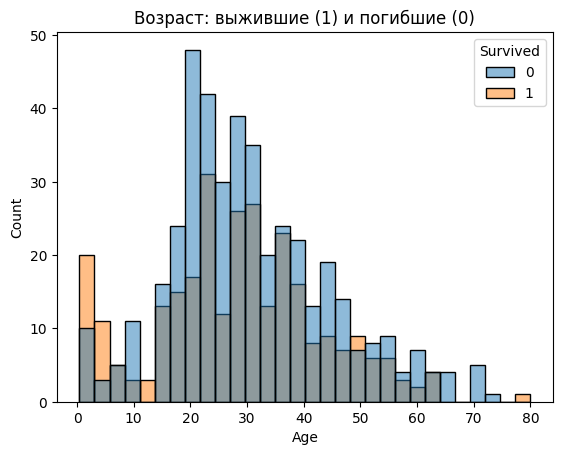

In [6]:
sns.histplot(data=df, x="Age", hue="Survived", bins=30)
plt.title("Возраст: выжившие (1) и погибшие (0)")
plt.show()


**Вывод.** Дети до 10 лет чаще выживали («женщины и дети первыми»). В 20–35 лет погибших намного больше — это в основном взрослые мужчины. Корреляция возраста с выживанием слабая (−0.08): эффект есть только у детей, а не «чем старше, тем хуже».

In [7]:
df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()["Survived"].sort_values() # кореляция каждого признака с выживаемостью

Pclass     -0.338481
Age        -0.077221
SibSp      -0.035322
Parch       0.081629
Fare        0.257307
Survived    1.000000
Name: Survived, dtype: float64

**Вывод по EDA.** 891 пассажир, дубликатов нет. Пропуски: Age (177), Cabin (687), Embarked (2). Погибли 62%, выжили 38% — классы неравные, поэтому главная метрика F1. Сильнее всего на выживание влияют пол (женщины 74%, мужчины 19%) и класс (1-й 63%, 3-й 24%). PassengerId, Name и Ticket почти уникальны — по ним модель может запомнить людей, их удаляем. Cabin удаляем из-за 77% пропусков.

In [8]:

# уд PassengerId, Name, Ticket (почти уникальны — модель запомнит конкретных пассажиров) и Cabin (77% пропусков)
X = df.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])
y = df["Survived"]
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)
print(X_train.shape, X_test.shape)

(712, 7) (179, 7)


X_train — 712 пассажиров, X_test — 179. Признаков 7.

Медиану возраста (28.5) и самый частый порт (S) считаем только по train, чтобы в обучение не попала информация из теста.

In [10]:
age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]
print("Медиана возраста:", age_median)
print("Самый частый порт:", embarked_mode)

Медиана возраста: 28.5
Самый частый порт: S


In [11]:
def prepare(data):
    data = data.copy() # копия, чтобы не испортить исходную таблицу
    data["Age"] = data["Age"].fillna(age_median) # пустой возраст пишем медиана
    data["Embarked"] = data["Embarked"].fillna(embarked_mode) # пустой порт пишем самый частый
    data["Sex"] = data["Sex"].map({"male": 0, "female": 1}) # пол => число
    data = pd.get_dummies(data, columns=["Embarked"], dtype=int) # порт => 3 столбца 0/1
    return data

X_train = prepare(X_train)
X_test = prepare(X_test)
X_train.head()


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
692,3,0,28.5,0,0,56.4958,0,0,1
481,2,0,28.5,0,0,0.0000,0,0,1
527,1,0,28.5,0,0,221.7792,0,0,1
855,3,1,18.0,0,1,9.3500,0,0,1
801,2,1,31.0,1,1,26.2500,0,0,1


In [12]:
# проверяем, что пропусков не осталось и столбцы в train и test совпадают
print("Пропусков в train:", X_train.isna().sum().sum())
print("Пропусков в test:", X_test.isna().sum().sum())
print("Столбцы совпадают:", list(X_train.columns) == list(X_test.columns))

Пропусков в train: 0
Пропусков в test: 0
Столбцы совпадают: True


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # запомнить среднее и разброс по train + перевести
X_test_scaled = scaler.transform(X_test) # тест — теми же числами

**Подготовка.** Удалили PassengerId, Name, Ticket, Cabin. Пропуски в Age заполнили медианой, в Embarked — самым частым портом (оба значения по train). Пол → 0/1, порт → 3 столбца 0/1 (one-hot), чтобы не придумывать портам порядок. Для SVM и KNN признаки масштабировали — они считают расстояния. Деревьям это не нужно.

In [14]:
def get_metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred), # доля всех правильных ответов
        precision_score(y_true, y_pred, zero_division=0), # из названных «выжил» — сколько реально выжили
        recall_score(y_true, y_pred), # из реально выживших — скольких нашли
        f1_score(y_true, y_pred), # баланс precision и recall
    ]

results = []

**Baseline.** Dummy всем ставит самый частый класс — «не выжил». Это нижняя планка.

In [15]:
dummy = DummyClassifier(strategy="most_frequent") # стратегия: всегда самый частый класс
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

results.append(["Dummy"] + get_metrics(y_test, y_pred_dummy))
print(results[-1])


['Dummy', 0.6145251396648045, 0.0, 0.0, 0.0]


**Результат Dummy:** Accuracy 0.615, остальные метрики 0. Accuracy высокая только потому, что погибших большинство (110 из 179). Ни одного выжившего Dummy не нашёл, поэтому F1 = 0. Значит, смотреть надо на F1, а не на Accuracy.

Confusion matrix: строки — правда, столбцы — прогноз. Dummy всех отнёс к «не выжил»: 110 угадал, 69 выживших пропустил.

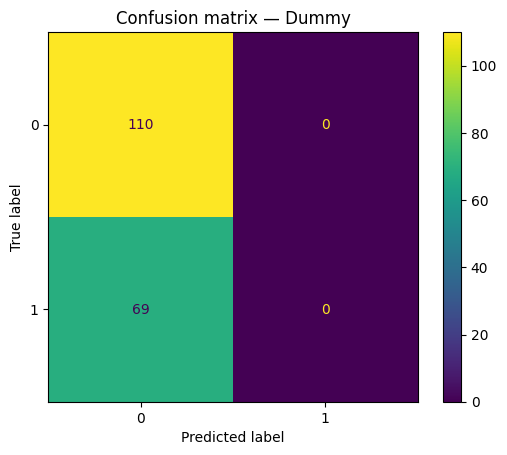

In [16]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dummy)
plt.title("Confusion matrix — Dummy")
plt.show()

In [17]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_pred_dt_train = dt.predict(X_train)

results.append(["Decision Tree"] + get_metrics(y_test, y_pred_dt))

print("train:", np.round(get_metrics(y_train, y_pred_dt_train), 3))
print("test: ", np.round(get_metrics(y_test, y_pred_dt), 3))


train: [0.983 0.996 0.96  0.978]
test:  [0.821 0.794 0.725 0.758]


**Decision Tree.** На тесте F1 = 0.758, порог пройден. Из 63 пассажиров, названных выжившими, верно 50 (13 ошибок). Из 69 выживших нашёл 50, пропустил 19.

На train F1 = 0.978 — почти без ошибок. Большой разрыв между train и test — это **переобучение**: дерево без ограничения глубины (23 уровня) запомнило обучающих пассажиров.

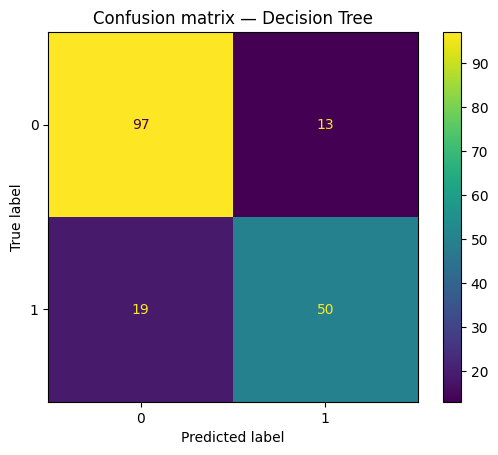

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt)
plt.title("Confusion matrix — Decision Tree")
plt.show()

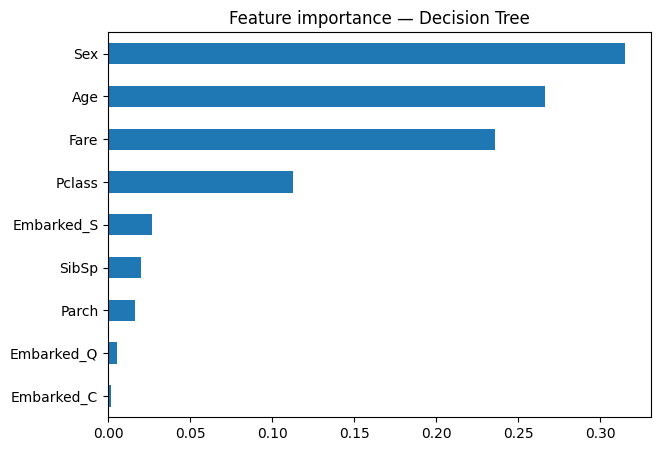

In [19]:
dt_importance = pd.Series(dt.feature_importances_, index=X_train.columns).sort_values()
dt_importance.plot.barh(figsize=(7, 5))
plt.title("Feature importance — Decision Tree")
plt.show()

**Вывод.** Главный признак — пол (0.32), как и в EDA. Age (0.27) и Fare (0.24) тоже высоко, но отчасти из-за переобучения: по ним удобно дробить пассажиров на мелкие группы. Pclass ниже (0.11) — его информацию дублирует Fare.

In [20]:
rf = RandomForestClassifier(
    n_estimators=300, # 300 деревьев
    random_state=RANDOM_STATE, # воспроизводимость
    n_jobs=-1, # все ядра процессора
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

results.append(["Random Forest"] + get_metrics(y_test, y_pred_rf))
print(np.round(results[-1][1:], 3))

[0.821 0.803 0.71  0.754]


**Вывод.** Random Forest: F1 = 0.754, почти как у дерева. Нашёл 49 из 69 выживших, ошибся в «выжил» 12 раз. Лес надёжнее дерева: он усредняет 300 деревьев.

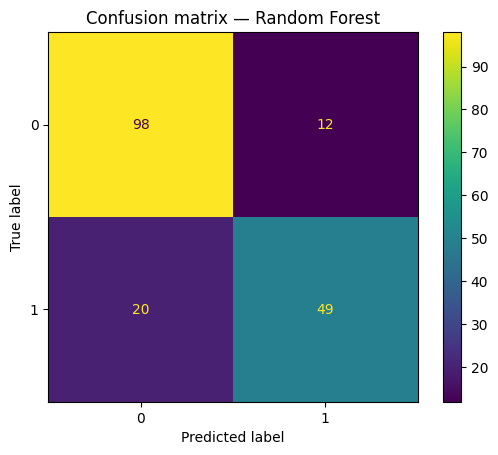

In [21]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf)
plt.title("Confusion matrix — Random Forest")
plt.show()

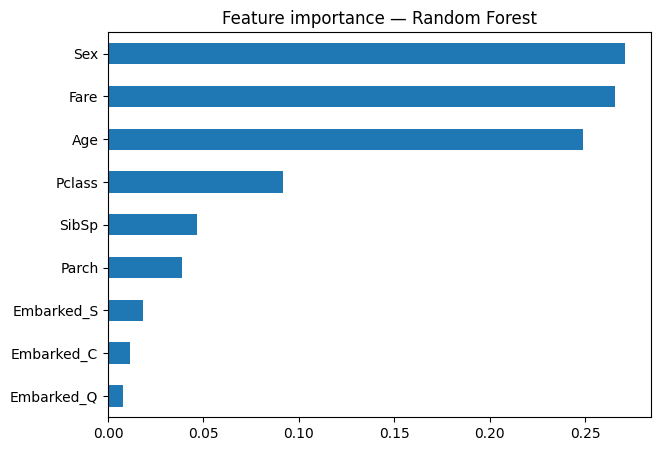

In [22]:
rf_importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
rf_importance.plot.barh(figsize=(7, 5))
plt.title("Feature importance — Random Forest")
plt.show()

**Вывод.** Главные признаки те же: пол (0.27), Fare (0.27), Age (0.25). Важность распределена ровнее, чем у дерева: в каждом узле лес выбирает из случайных признаков, и пол доступен не всегда.

In [23]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

results.append(["Gradient Boosting"] + get_metrics(y_test, y_pred_gb))
print(np.round(results[-1][1:], 3))

[0.799 0.789 0.652 0.714]


**Вывод.** Gradient Boosting: F1 = 0.714, порог пройден впритык. Пропустил 24 выживших — больше, чем лес (20). Скорее всего, с параметрами по умолчанию он немного недообучен. Зато почти не переобучается: F1 на train 0.866.

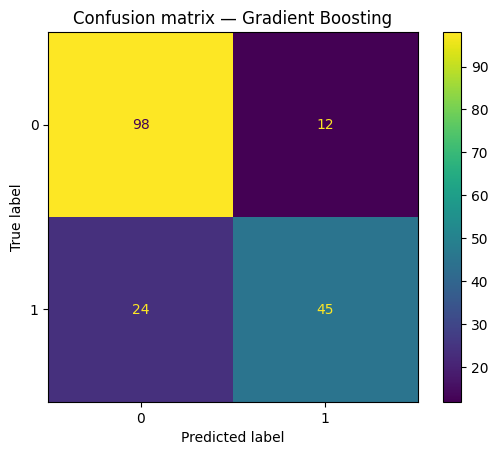

In [24]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gb)
plt.title("Confusion matrix — Gradient Boosting")
plt.show()

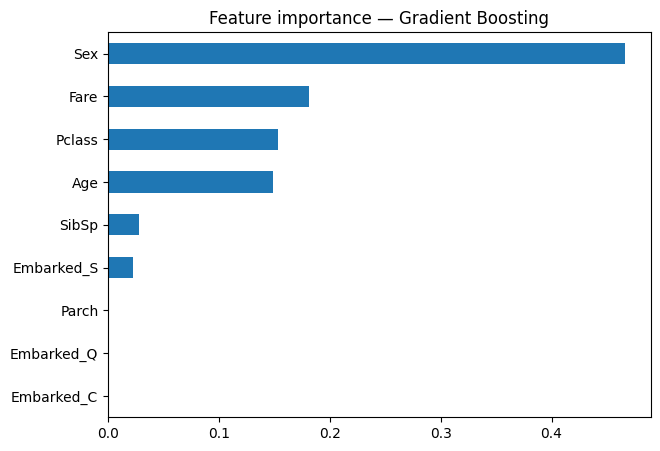

In [25]:
gb_importance = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values()
gb_importance.plot.barh(figsize=(7, 5))
plt.title("Feature importance — Gradient Boosting")
plt.show()

**Вывод.** У бустинга пол забирает почти половину важности (0.47): первые деревья исправляют самую большую ошибку, а это разделение по полу. Age и Fare важны меньше, чем у леса — деревья мелкие и не дробят пассажиров.

In [26]:
svm = SVC(random_state=RANDOM_STATE)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

results.append(["SVM"] + get_metrics(y_test, y_pred_svm))
print(np.round(results[-1][1:], 3))

[0.816 0.86  0.623 0.723]


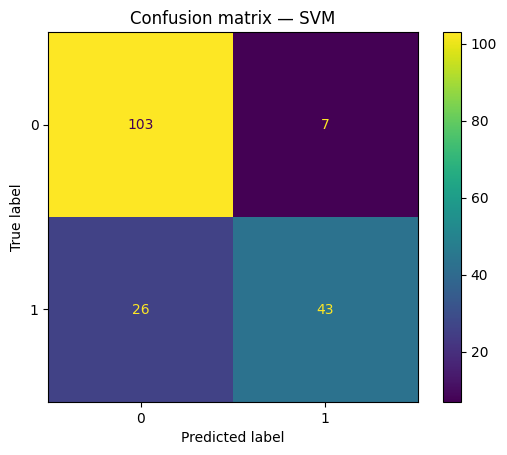

In [27]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm)
plt.title("Confusion matrix — SVM")
plt.show()

**Вывод.** SVM: F1 = 0.723. Самый высокий Precision (0.86): если сказал «выжил» — почти всегда прав. Но пропустил 26 выживших — больше всех. Модель «осторожная».

У SVM и KNN нет feature importance: они считают расстояния сразу по всем признакам, а не выбирают признаки, как деревья.

In [28]:
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

results.append(["KNN"] + get_metrics(y_test, y_pred_knn))
print(np.round(results[-1][1:], 3))


[0.816 0.8   0.696 0.744]


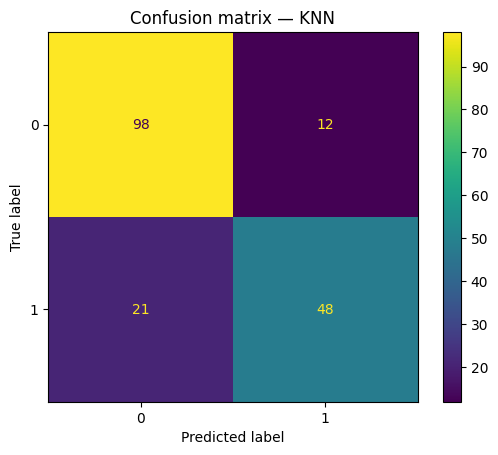

In [29]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn)
plt.title("Confusion matrix — KNN")
plt.show()

**Вывод.** KNN: F1 = 0.744, почти как лес. Пропустил 21 выжившего. Метод «посмотри на 5 похожих пассажиров» работает, потому что похожие по полу, классу и возрасту люди имели похожую судьбу.

In [30]:
svm_raw = SVC(random_state=RANDOM_STATE).fit(X_train, y_train)
knn_raw = KNeighborsClassifier().fit(X_train, y_train)

print("SVM  без масштабирования F1:", round(f1_score(y_test, svm_raw.predict(X_test)), 3))
print("KNN  без масштабирования F1:", round(f1_score(y_test, knn_raw.predict(X_test)), 3))

SVM  без масштабирования F1: 0.32
KNN  без масштабирования F1: 0.565


**Вывод.** Без масштабирования SVM падает с 0.723 до 0.32, KNN — с 0.744 до 0.565. Без него расстояние почти целиком определяет цена билета (до 512), а пол (0 или 1) почти не влияет. Деревьям масштаб не нужен — они сравнивают признак с порогом.

In [31]:
results_df = pd.DataFrame(results, columns=["Модель", "Accuracy", "Precision", "Recall", "F1"])
results_df.round(3)

,Модель,Accuracy,Precision,Recall,F1
0,Dummy,0.615,0.000,0.000,0.000
1,Decision Tree,0.821,0.794,0.725,0.758
2,Random Forest,0.821,0.803,0.710,0.754
3,Gradient Boosting,0.799,0.789,0.652,0.714
4,SVM,0.816,0.860,0.623,0.723
5,KNN,0.816,0.800,0.696,0.744


**Вывод.** Порог прошли все 5 моделей, Dummy — нет. Лучшие — дерево (0.758) и лес (0.754), разница в 1–2 пассажира. Лучшей считаем **Random Forest**: дерево переобучено, лес стабильнее.

У всех моделей Recall ниже Precision — они чаще пропускают выживших, чем ошибочно «спасают» погибших, потому что погибших больше. Accuracy у всех почти одинаковая (0.80–0.82), разница видна по F1.

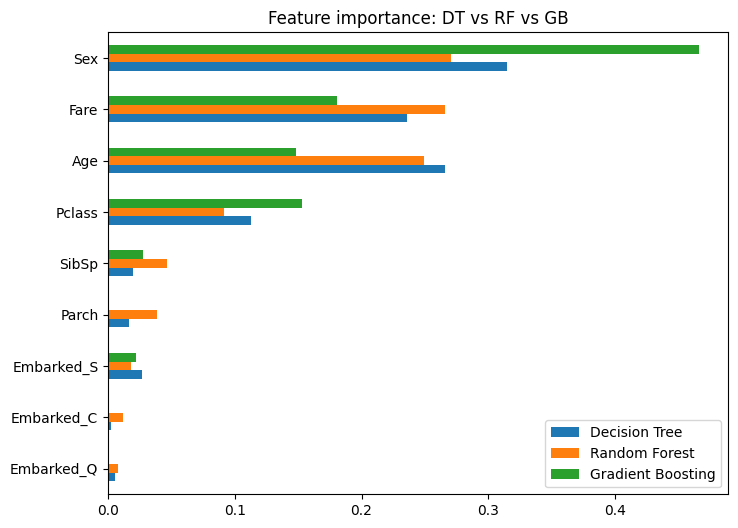

In [32]:
importance_df = pd.DataFrame({
    "Decision Tree": dt_importance,
    "Random Forest": rf_importance,
    "Gradient Boosting": gb_importance,
}).sort_values("Random Forest")

importance_df.plot.barh(figsize=(8, 6))
plt.title("Feature importance: DT vs RF vs GB")
plt.show()

**Вывод.** У всех трёх моделей главный признак — пол, как и в EDA. Дальше Fare, Age, Pclass. У бустинга пол важнее всего (0.47), у леса важность распределена ровнее. Pclass ниже, чем ожидалось, — его дублирует Fare.

**Важный признак — это причина выживания?** Нет. Важность показывает, что признак помогает *угадать*, а не что он *спасал*. Дорогой билет сам не спасал — он означал 1-й класс и места ближе к шлюпкам. И пол важен не сам по себе, а из-за правила «женщины и дети первыми».

## Анализ ошибок лучшей модели (Random Forest)

Весь анализ ниже — для Random Forest (pred = y_pred_rf). Кроме последней ячейки с PassengerId: там отдельный лес для проверки.

In [33]:
errors = df.loc[X_test.index, ["Name", "Sex", "Age", "Pclass", "Fare"]].copy()
errors["true"] = y_test
errors["pred"] = y_pred_rf
errors["wrong"] = errors["true"] != errors["pred"]
errors.head()

,Name,Sex,Age,Pclass,Fare,true,pred,wrong
565,"Davies, Mr. Alfred J",male,24.0,3,24.1500,0,0,False
160,"Cribb, Mr. John Hatfield",male,44.0,3,16.1000,0,0,False
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.2250,1,0,True
860,"Hansen, Mr. Claus Peter",male,41.0,3,14.1083,0,0,False
241,"Murphy, Miss. Katherine ""Kate""",female,NaN,3,15.5000,1,1,False


In [34]:
print("Доля ошибок по полу:")
print(errors.groupby("Sex")["wrong"].mean().round(2))
print("\nДоля ошибок по классу:")
print(errors.groupby("Pclass")["wrong"].mean().round(2))


Доля ошибок по полу:
Sex
female    0.13
male      0.20
Name: wrong, dtype: float64

Доля ошибок по классу:
Pclass
1    0.24
2    0.12
3    0.17
Name: wrong, dtype: float64


**Вывод.** Лес чаще ошибается на мужчинах (20% против 13%) и в 1-м классе (24%). Модель выучила «мужчина — погиб, женщина — выжила» и ошибается на исключениях: на выживших мужчинах и погибших женщинах.

In [35]:
# пропущенные выжившие (FN): правда 1, прогноз 0
errors[(errors["true"] == 1) & (errors["pred"] == 0)]

,Name,Sex,Age,Pclass,Fare,true,pred,wrong
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.2250,1,0,True
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.0,3,17.4000,1,0,True
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,52.0000,1,0,True
455,"Jalsevac, Mr. Ivan",male,29.0,3,7.8958,1,0,True
489,"Coutts, Master. Eden Leslie ""Neville""",male,9.0,3,15.9000,1,0,True
165,"Goldsmith, Master. Frank John William ""Frankie""",male,9.0,3,20.5250,1,0,True
17,"Williams, Mr. Charles Eugene",male,NaN,2,13.0000,1,0,True
679,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,1,512.3292,1,0,True
55,"Woolner, Mr. Hugh",male,NaN,1,35.5000,1,0,True
570,"Harris, Mr. George",male,62.0,2,10.5000,1,0,True


In [36]:
# ложно «спасённые» (FP): правда 0, прогноз 1
errors[(errors["true"] == 0) & (errors["pred"] == 1)]

,Name,Sex,Age,Pclass,Fare,true,pred,wrong
536,"Butt, Major. Archibald Willingham",male,45.0,1,26.5500,0,1,True
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.5500,0,1,True
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,7.6292,0,1,True
593,"Bourke, Miss. Mary",female,NaN,3,7.7500,0,1,True
442,"Petterson, Mr. Johan Emil",male,25.0,3,7.7750,0,1,True
501,"Canavan, Miss. Mary",female,21.0,3,7.7500,0,1,True
92,"Chaffee, Mr. Herbert Fuller",male,46.0,1,61.1750,0,1,True
245,"Minahan, Dr. William Edward",male,44.0,1,90.0000,0,1,True
826,"Lam, Mr. Len",male,NaN,3,56.4958,0,1,True
137,"Futrelle, Mr. Jacques Heath",male,37.0,1,53.1000,0,1,True


**Вывод.** Пропущенных выживших (FN, 20) больше, чем ложно «спасённых» (FP, 12). FN — почти одни мужчины, в том числе мальчики (Davies и Coutts, 8–9 лет) и мужчины 1-го класса: модель видит «мужчина» и ставит «погиб». FP — в основном женщины 3-го класса и мужчины 1-го класса. Например, Allison — девочка 2 лет из 1-го класса: по всем признакам должна была выжить, но погибла. Такие случаи по этим данным не угадать.

Проверка: обучаем такой же лес, но оставляем PassengerId — просто номер строки.

In [37]:
# проверка на «запоминание»: такой же лес, но с PassengerId (номер строки)
X_id = df.drop(columns=["Survived", "Name", "Ticket", "Cabin"])   # PassengerId оставили
X_id_train = prepare(X_id.loc[X_train.index])                      # те же пассажиры, что в train
X_id_test = prepare(X_id.loc[X_test.index])                        # те же, что в test

rf_id = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_id.fit(X_id_train, y_train)

print("F1 с PassengerId:", round(f1_score(y_test, rf_id.predict(X_id_test)), 3))
pd.Series(rf_id.feature_importances_, index=X_id_train.columns).sort_values(ascending=False).round(3)

F1 с PassengerId: 0.744


Sex            0.245
Fare           0.202
PassengerId    0.188
Age            0.170
Pclass         0.082
SibSp          0.041
Parch          0.032
Embarked_S     0.018
Embarked_C     0.013
Embarked_Q     0.009
dtype: float64

**Вывод.** С PassengerId лес поставил номер на 3-е место по важности (0.19), хотя номер строки никак не влияет на выживание. Модель просто запоминает конкретных пассажиров по номеру. На тесте это не помогает: F1 упал с 0.754 до 0.744. Поэтому PassengerId, Name и Ticket мы удалили.

## Улучшение модели

По анализу ошибок среди пропущенных выживших есть мальчики (Davies, Coutts, Goldsmith, 8–9 лет): модель отнесла их к мужчинам и предсказала «погиб». Добавим два признака:

- **Title** — обращение из имени: Mr, Mrs, Miss, Master (мальчик), Rare (Dr, Rev, военные и т.д.). Само имя не используем — только обращение, оно не уникально (у 517 человек «Mr»), так что запомнить людей по нему нельзя.
- **FamilySize** — размер семьи на борту: SibSp + Parch + 1.

Модель выбираем по **кросс-валидации на train**, тест смотрим один раз в конце.

In [38]:
df2 = df.copy()
df2["Title"] = df2["Name"].str.extract(r",\s*([^\.]+)\.")[0]          # текст между запятой и точкой: "Braund, Mr. Owen" → "Mr"
df2["Title"] = df2["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})   # французские и редкие формы
df2.loc[~df2["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"     # остальные (Dr, Rev, Col...) → Rare
df2["FamilySize"] = df2["SibSp"] + df2["Parch"] + 1

df2.groupby("Title")["Survived"].agg(["count", "mean"]).round(2)

,count,mean
Title,,
Master,40,0.57
Miss,185,0.70
Mr,517,0.16
Mrs,126,0.79
Rare,23,0.35


Выжили: Mr — 16%, Master (мальчики) — 57%, Miss — 70%, Mrs — 79%, Rare — 35%. Мальчики выживали намного чаще взрослых мужчин, и теперь модель это видит.

In [ ]:
X2 = df2.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])
X2_train = X2.loc[X_train.index] # те же пассажиры, что в основном train
X2_test = X2.loc[X_test.index] # и в основном test

# пропуски в возрасте — медианой по обращению (у Master ~3.5 года, у Mr ~30), считаем по train
age_by_title = X2_train.groupby("Title")["Age"].median()

def prepare2(data):
    data = data.copy()
    data["Age"] = data["Age"].fillna(data["Title"].map(age_by_title))
    data["Embarked"] = data["Embarked"].fillna(embarked_mode)
    data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
    data = pd.get_dummies(data, columns=["Embarked", "Title"], dtype=int)
    return data

X2_train = prepare2(X2_train)
X2_test = prepare2(X2_test).reindex(columns=X2_train.columns, fill_value=0) # одинаковые столбцы в train и test
print(X2_train.shape, X2_test.shape)
X2_train.head()

(712, 15) (179, 15)


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
692,3,0,30.0,0,0,56.4958,1,0,0,1,0,0,1,0,0
481,2,0,30.0,0,0,0.0000,1,0,0,1,0,0,1,0,0
527,1,0,30.0,0,0,221.7792,1,0,0,1,0,0,1,0,0
855,3,1,18.0,0,1,9.3500,2,0,0,1,0,0,0,1,0
801,2,1,31.0,1,1,26.2500,3,0,0,1,0,0,0,1,0


Сравниваем несколько моделей по 5-кратной кросс-валидации на train. Для SVM и KNN масштабирование делаем внутри `make_pipeline`: так scaler обучается заново на каждой части train и не «видит» проверочную часть.

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "RF": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "RF max_depth=5": RandomForestClassifier(n_estimators=300, max_depth=5, random_state=RANDOM_STATE, n_jobs=-1),
    "RF max_depth=7": RandomForestClassifier(n_estimators=300, max_depth=7, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM": make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)),
    "KNN k=5": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "KNN k=15": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}

cv_results = []
for name, model in candidates.items():
    scores = cross_val_score(model, X2_train, y_train, cv=cv, scoring="f1") # 5 значений F1
    cv_results.append([name, scores.mean(), scores.std()])

pd.DataFrame(cv_results, columns=["Модель", "F1 (CV, среднее)", "разброс"]).sort_values("F1 (CV, среднее)", ascending=False).round(3)

,Модель,"F1 (CV, среднее)",разброс
1,RF max_depth=5,0.766,0.027
4,SVM,0.759,0.035
2,RF max_depth=7,0.753,0.031
6,KNN k=15,0.747,0.052
5,KNN k=5,0.745,0.030
3,Gradient Boosting,0.744,0.038
0,RF,0.729,0.022


По кросс-валидации лучший — **Random Forest с max_depth=5**. Ограничение глубины не даёт деревьям запоминать отдельных пассажиров. Обучаем его на всём train и **один раз** проверяем на тесте.

In [41]:
best = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=RANDOM_STATE, n_jobs=-1)
best.fit(X2_train, y_train)
y_pred_best = best.predict(X2_test)

results.append(["RF + Title, FamilySize"] + get_metrics(y_test, y_pred_best))
results_df = pd.DataFrame(results, columns=["Модель", "Accuracy", "Precision", "Recall", "F1"])
results_df.round(3)

,Модель,Accuracy,Precision,Recall,F1
0,Dummy,0.615,0.000,0.000,0.000
1,Decision Tree,0.821,0.794,0.725,0.758
2,Random Forest,0.821,0.803,0.710,0.754
3,Gradient Boosting,0.799,0.789,0.652,0.714
4,SVM,0.816,0.860,0.623,0.723
5,KNN,0.816,0.800,0.696,0.744
6,"RF + Title, FamilySize",0.827,0.797,0.739,0.767


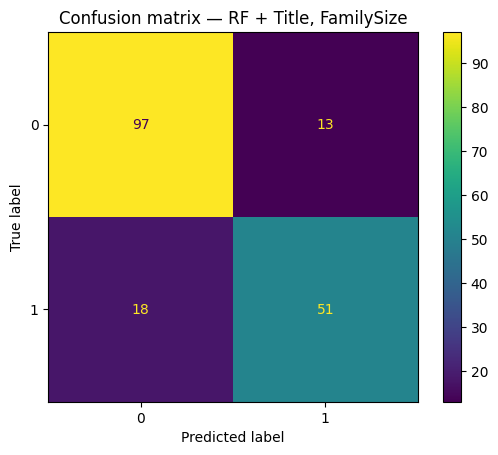

In [42]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best)
plt.title("Confusion matrix — RF + Title, FamilySize")
plt.show()

**Вывод.** С новыми признаками и ограничением глубины F1 на тесте вырос с 0.754 до 0.767. Модель выбирали по кросс-валидации, не глядя на тест. Главное, что помогло, — обращение: Master подсказывает, что пассажир — мальчик, и возраст для пропусков теперь берётся по обращению, а не одной общей медианой. Ограничение глубины уменьшило переобучение.

Прирост небольшой: на тесте из 179 пассажиров это 1–2 человека, так что на другой выборке результат может немного отличаться.

## Общий вывод

Все 5 моделей прошли порог F1 > 0.70. Лучшая — Random Forest (F1 0.754). Главный признак у всех — пол, дальше цена билета, возраст и класс, как и в EDA. SVM и KNN работают только с масштабированием. Чаще всего модели пропускают выживших мужчин, особенно мальчиков и мужчин 1-го класса. После добавления обращения (Title) и размера семьи и выбора модели по кросс-валидации F1 вырос до 0.767 (Random Forest с max_depth=5).